## 1. Data Loading and Initial Exploration

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42

# Visualization settings
sns.set_theme(style="whitegrid", palette="Set2")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "IT_customer_churn.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Dataset shape: {df.shape}")

Dataset loaded successfully!
Dataset shape: (7043, 20)


In [4]:
# Display first five records
display(df.head())

# Display last five records
display(df.tail())

# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset information:")
df.info()

# Statistical summary
display(df.describe(include="all").T)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


Number of rows: 7043
Number of columns: 20

Column names:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str  

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.00,NaN,NaN,NaN,0.16,0.37,0.00,0.00,0.00,0.00,1.00
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.00,NaN,NaN,NaN,32.37,24.56,0.00,9.00,29.00,55.00,72.00
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineBackup,7043,3,No,3088,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100)
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage
gender,0,0.00
SeniorCitizen,0,0.00
TotalCharges,0,0.00
MonthlyCharges,0,0.00
PaymentMethod,0,0.00
PaperlessBilling,0,0.00
Contract,0,0.00
StreamingMovies,0,0.00
StreamingTV,0,0.00
TechSupport,0,0.00


In [6]:
dtype_summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": df.nunique().values
})

display(dtype_summary)

,Column,Data Type,Unique Values
0,gender,str,2
1,SeniorCitizen,int64,2
2,Partner,str,2
3,Dependents,str,2
4,tenure,int64,73
5,PhoneService,str,2
6,MultipleLines,str,3
7,InternetService,str,3
8,OnlineSecurity,str,3
9,OnlineBackup,str,3


## 2. Target Variable Analysis

In [7]:
TARGET_COLUMN = "Churn"

print("Target distribution:")
display(df[TARGET_COLUMN].value_counts())

print("\nTarget distribution (%):")
display(
    df[TARGET_COLUMN]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Target distribution (%):


Churn
No    73.46
Yes   26.54
Name: proportion, dtype: float64

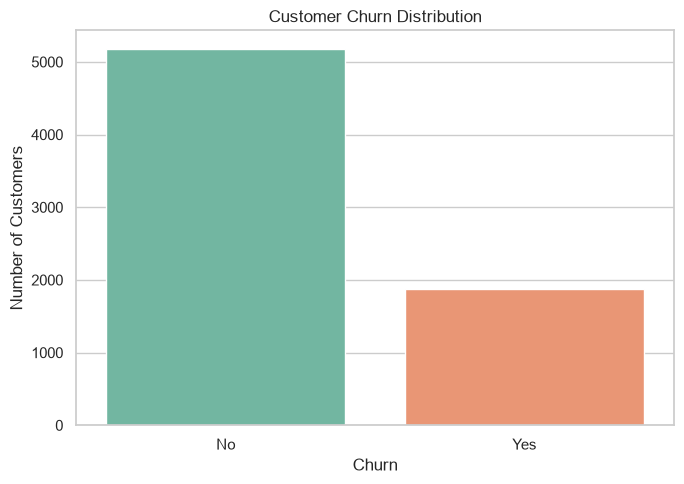

In [11]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x=TARGET_COLUMN,
    hue=TARGET_COLUMN,
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

## 3. Data Cleaning

In [12]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

display(df[df["TotalCharges"].isnull()].head(15))

TotalCharges data type: float64
Missing TotalCharges: 11


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [13]:
print("Shape before removing duplicates:", df.shape)

df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Shape before removing duplicates: (7043, 20)
Shape after removing duplicates: (7021, 20)
Remaining duplicates: 0


In [14]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("\nData types:")
display(df.dtypes)

print("\nDuplicate records:", df.duplicated().sum())

Dataset shape: (7021, 20)

Missing values:


TotalCharges    11
dtype: int64


Data types:


gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


Duplicate records: 0


## 4. Exploratory Data Analysis (EDA)

In [15]:
numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical features:", numerical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


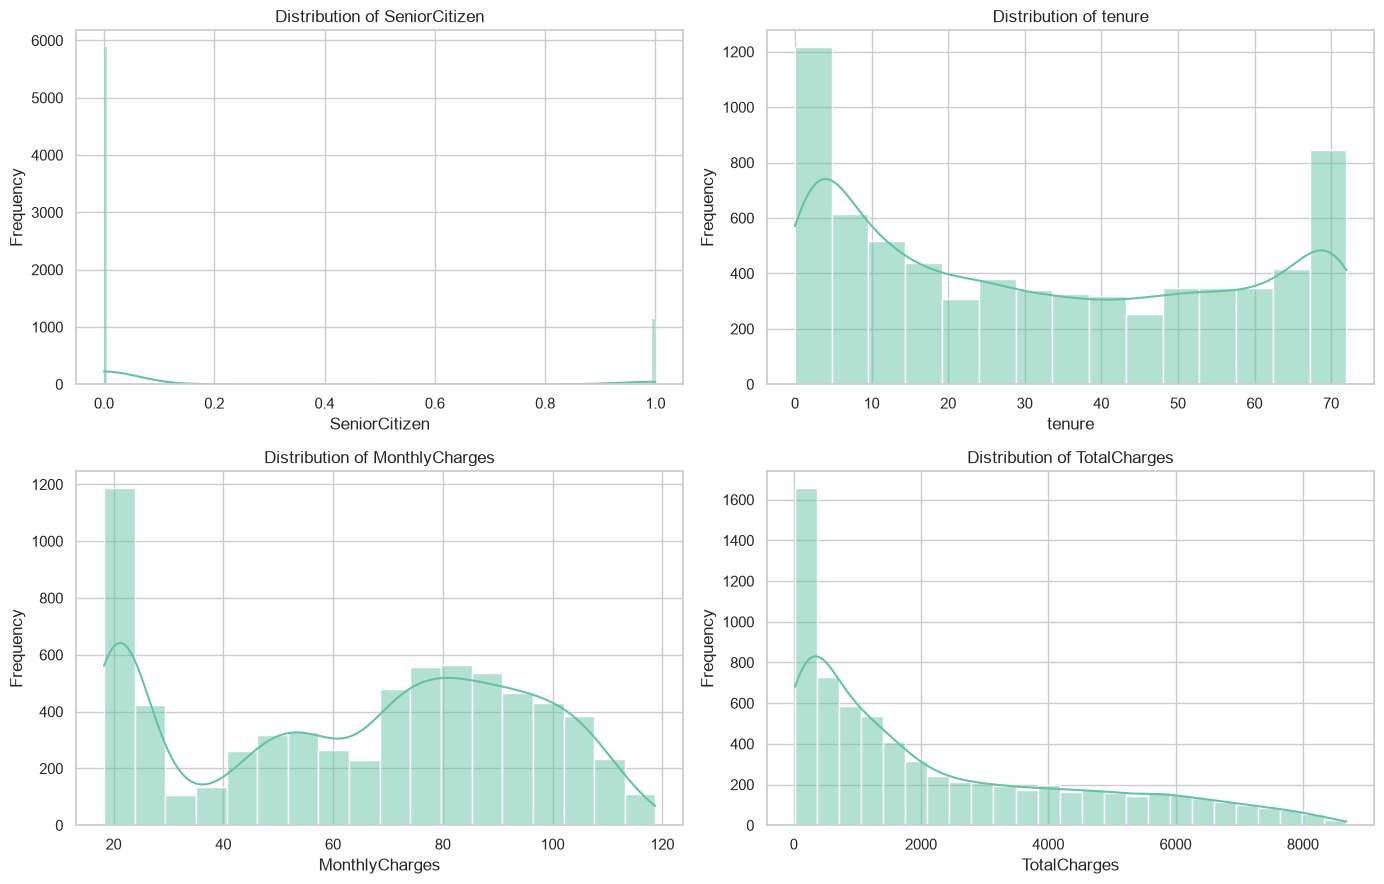

In [16]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9)
)

axes = axes.flatten()

for i, col in enumerate(numerical_features):

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

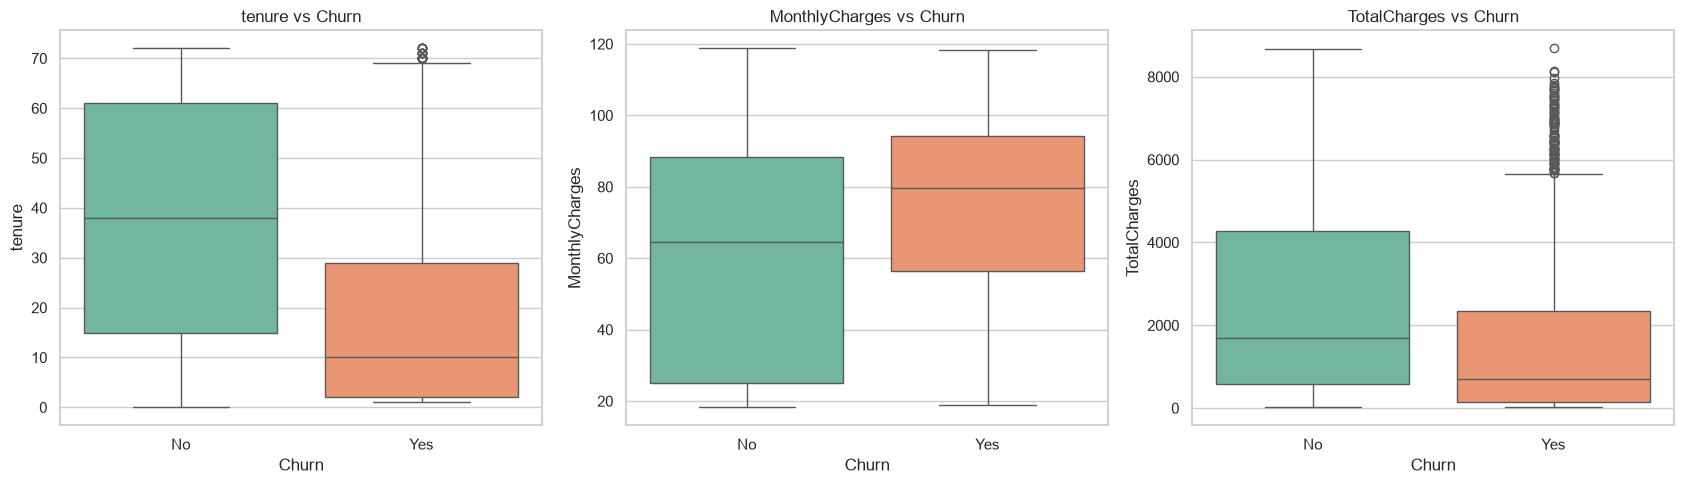

In [17]:
continuous_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

for i, col in enumerate(continuous_features):

    sns.boxplot(
        data=df,
        x="Churn",
        y=col,
        hue="Churn",
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} vs Churn")

plt.tight_layout()
plt.show()

In [18]:
categorical_features = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

categorical_features.remove("Churn")

print("Categorical features:")
print(categorical_features)

print("\nNumber of categorical features:", len(categorical_features))

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of categorical features: 15


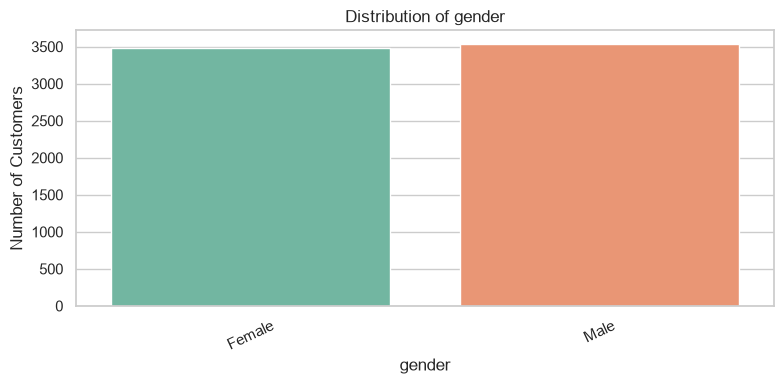

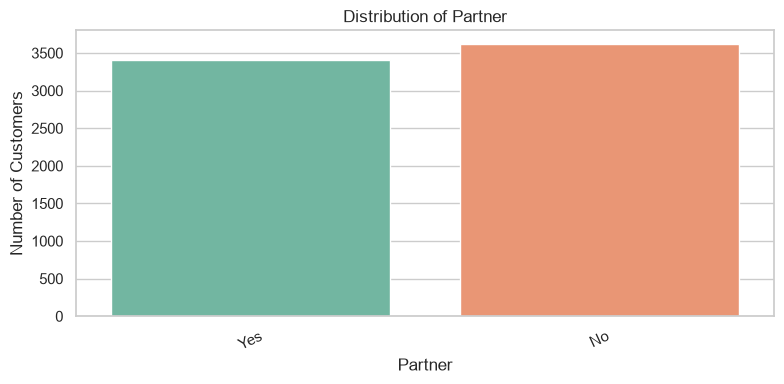

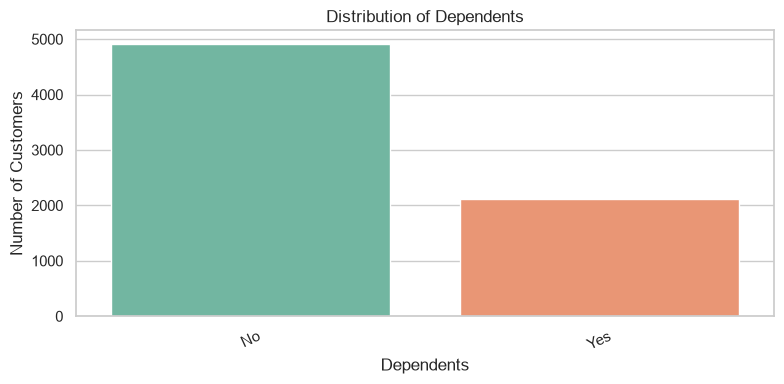

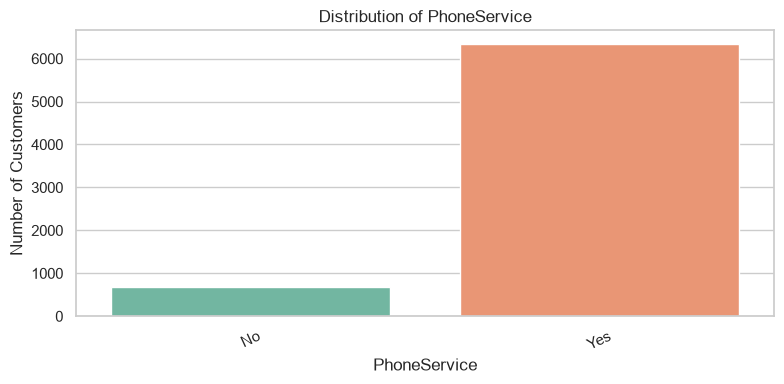

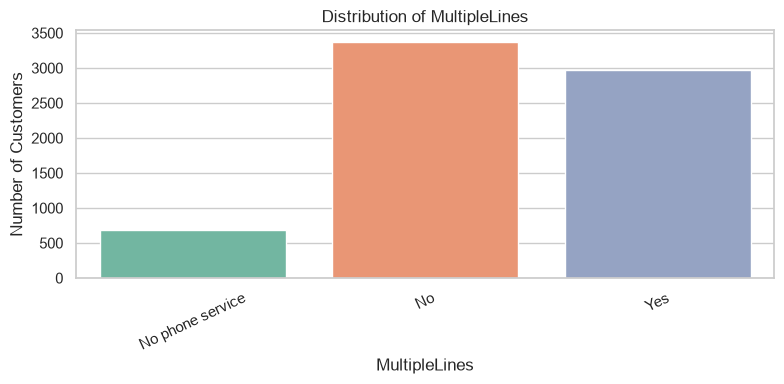

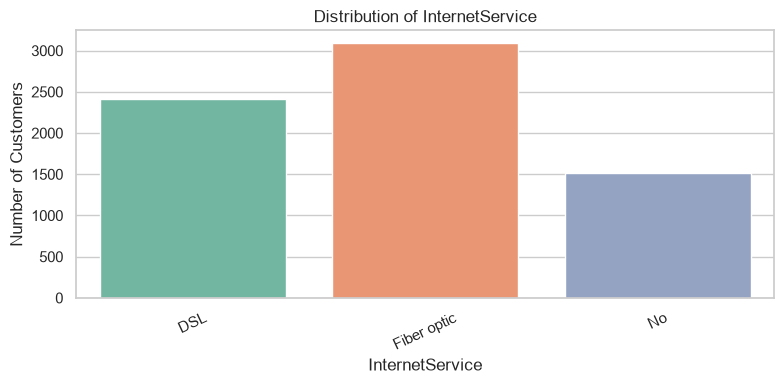

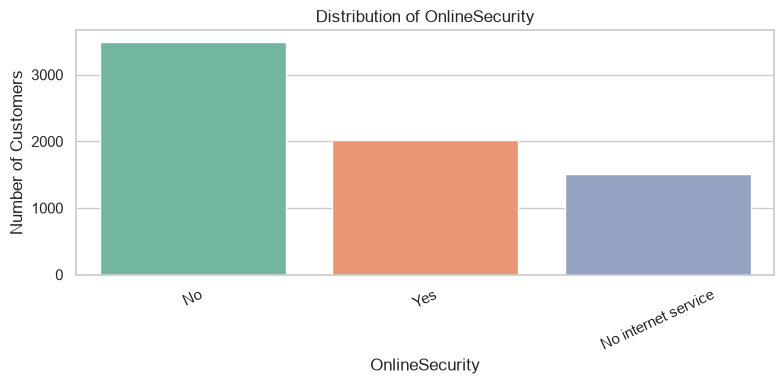

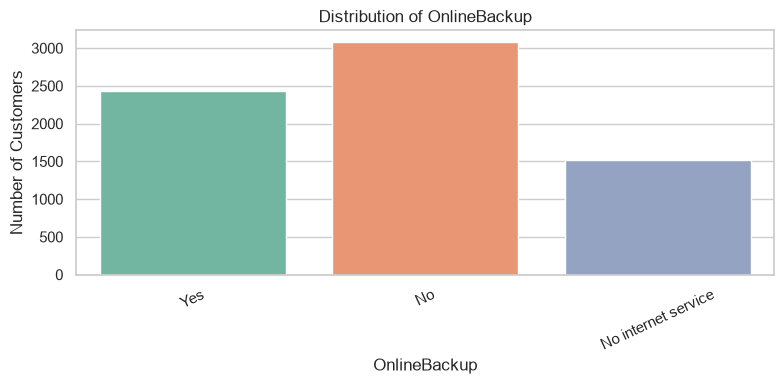

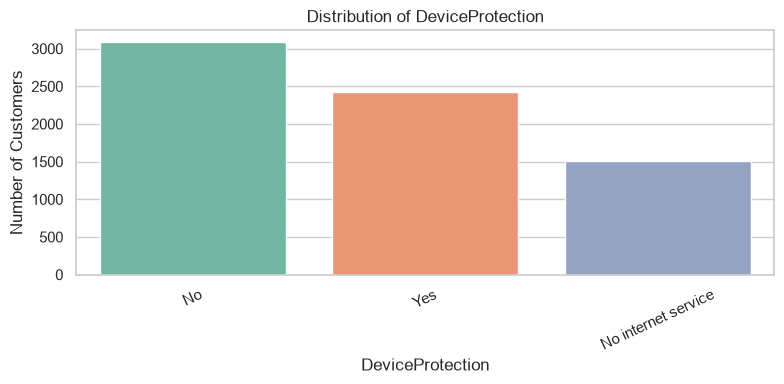

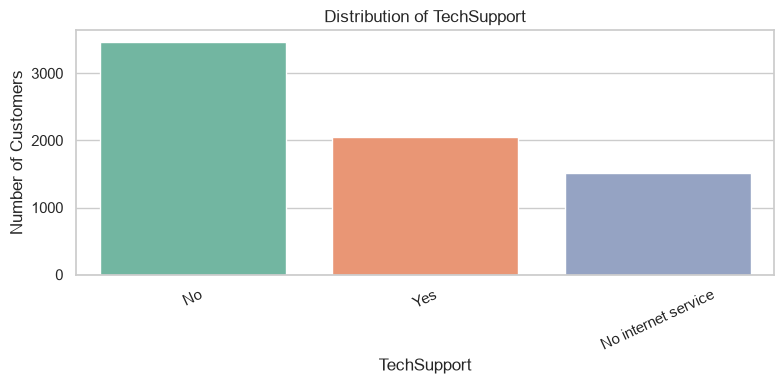

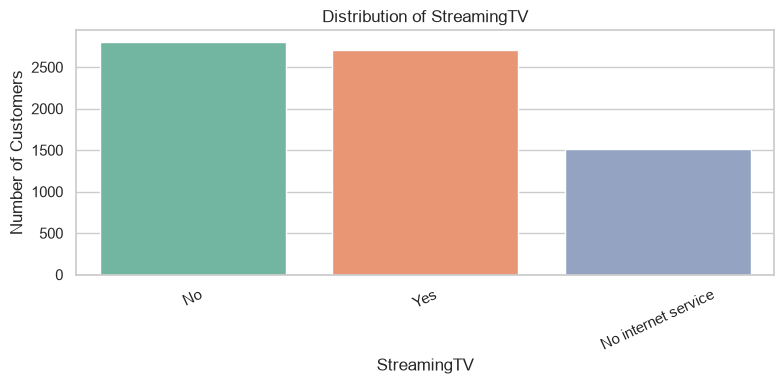

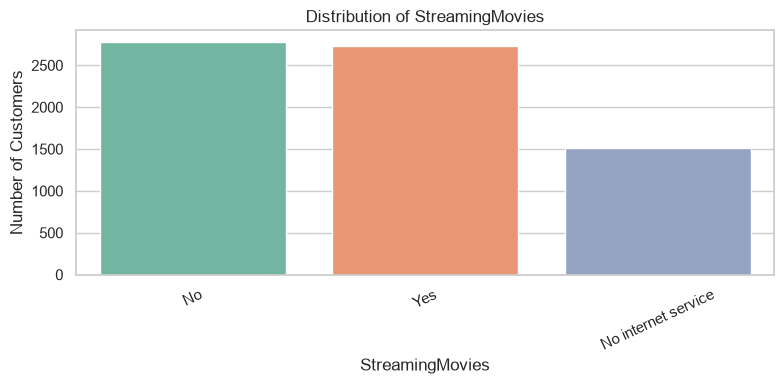

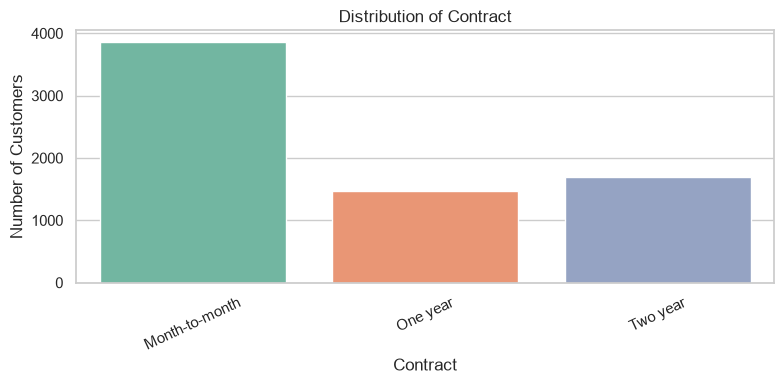

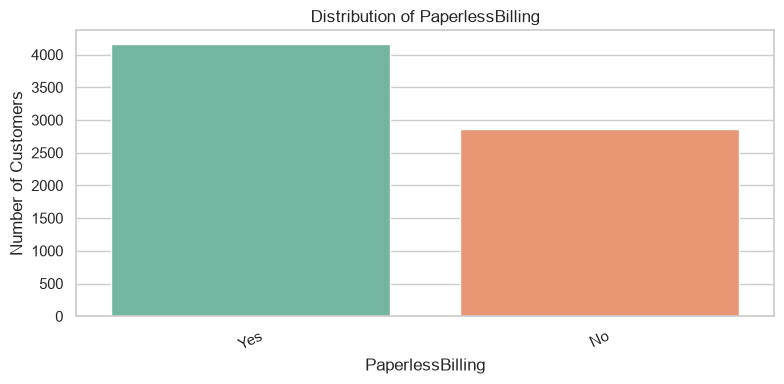

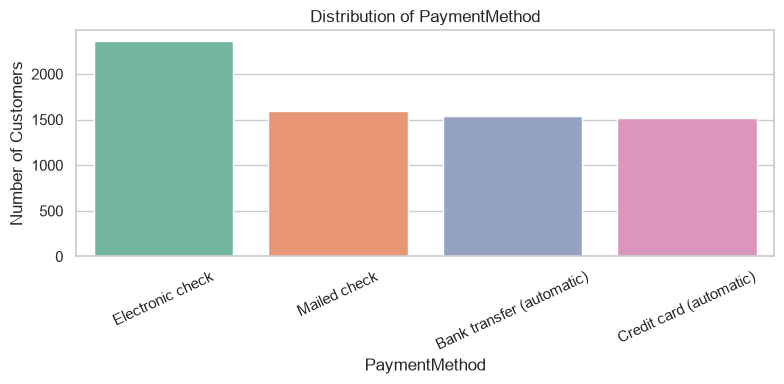

In [19]:
for col in categorical_features:

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=col,
        hue=col,
        legend=False
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=25)

    plt.tight_layout()
    plt.show()

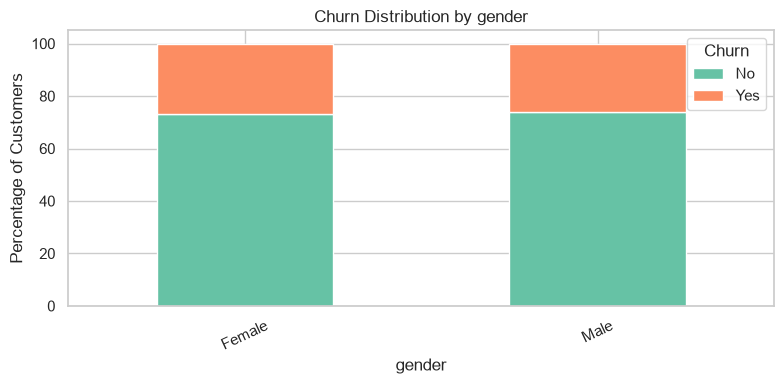

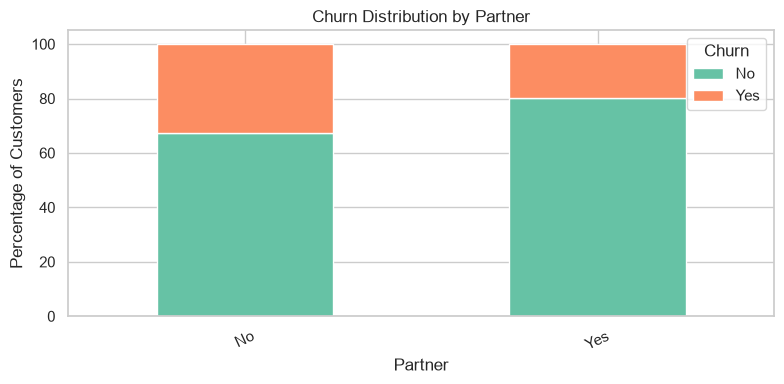

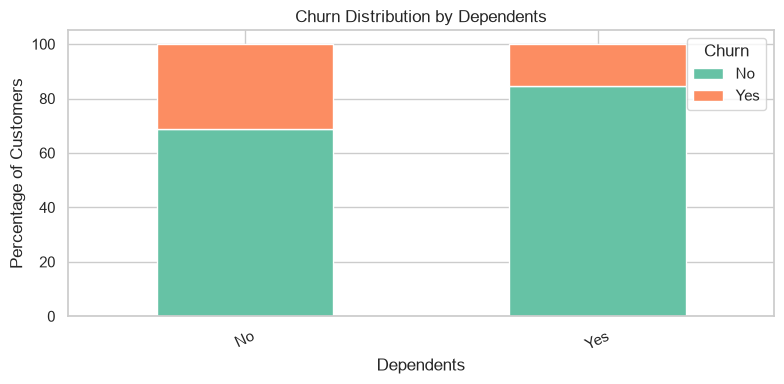

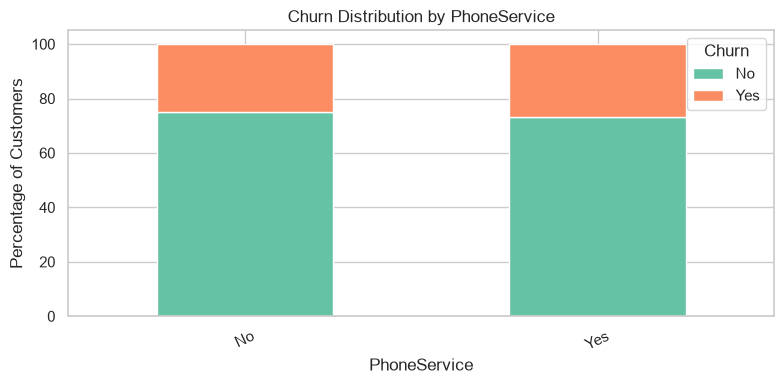

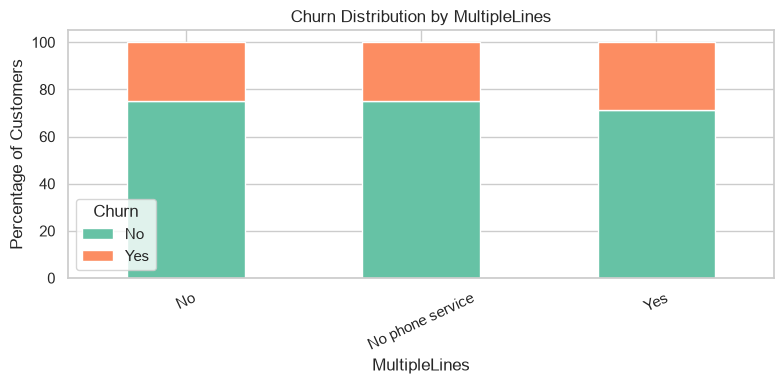

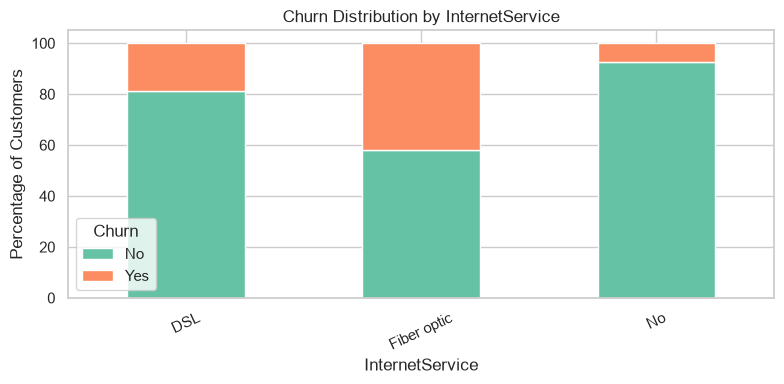

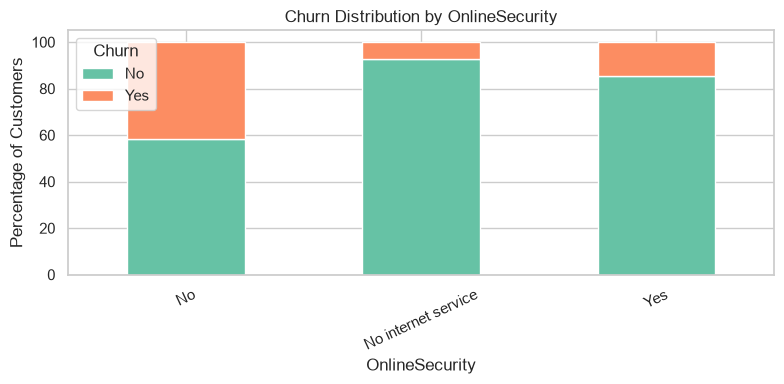

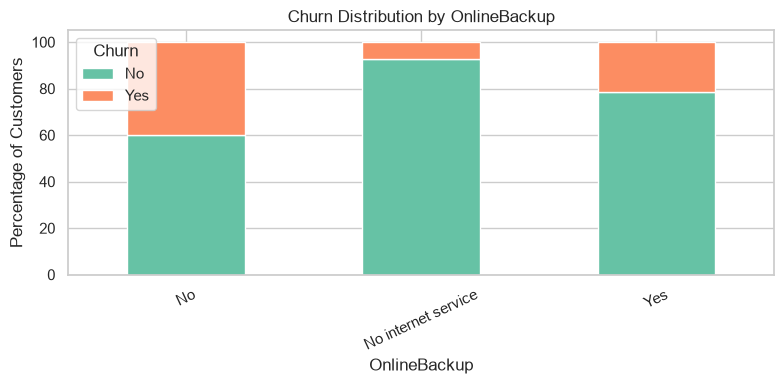

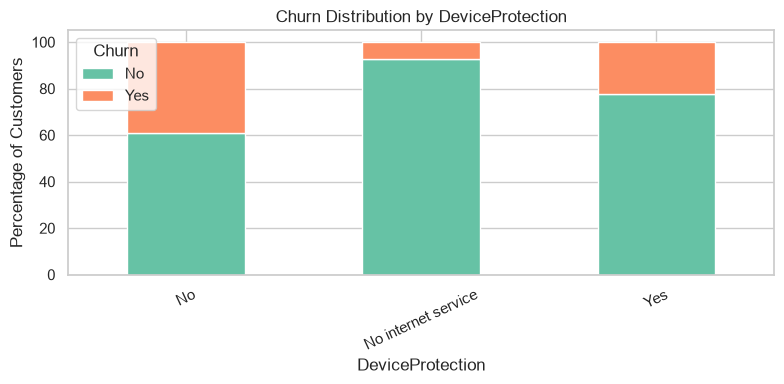

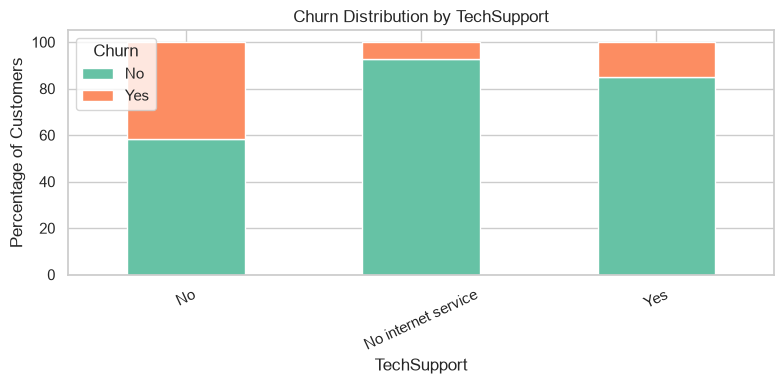

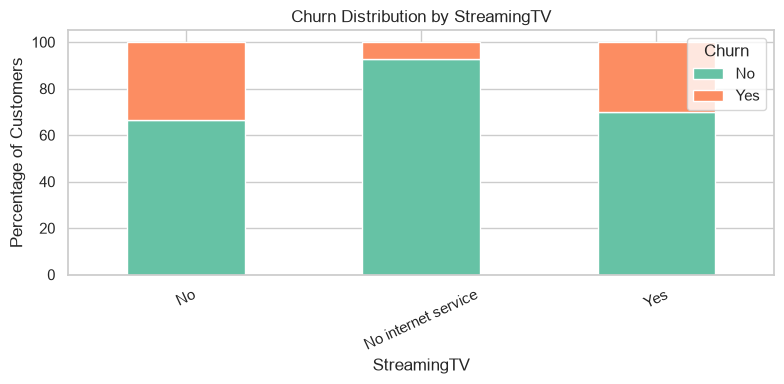

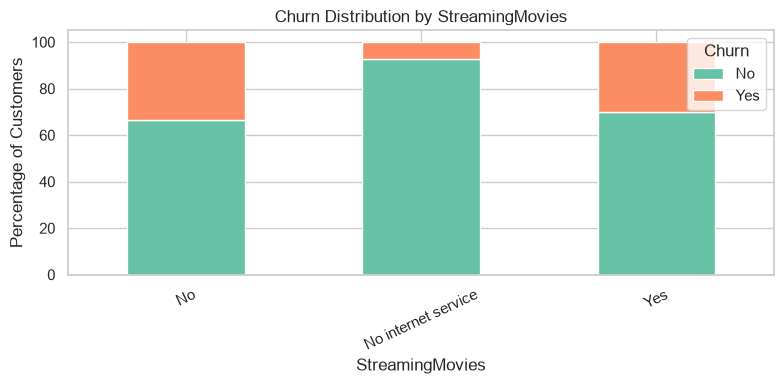

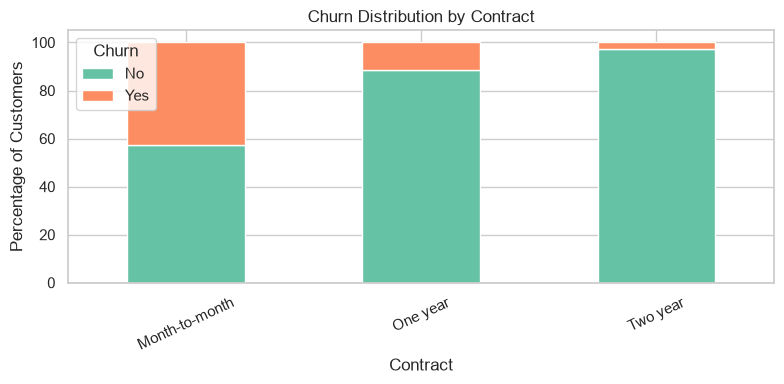

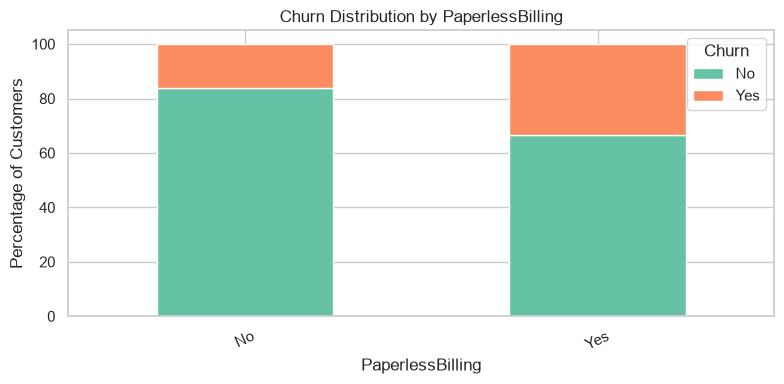

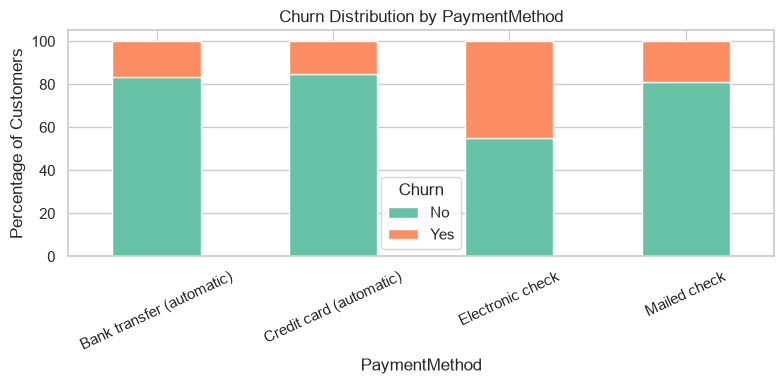

In [20]:
for col in categorical_features:

    churn_rate = pd.crosstab(
        df[col],
        df["Churn"],
        normalize="index"
    ) * 100

    churn_rate.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 4)
    )

    plt.title(f"Churn Distribution by {col}")
    plt.xlabel(col)
    plt.ylabel("Percentage of Customers")
    plt.legend(title="Churn")
    plt.xticks(rotation=25)

    plt.tight_layout()
    plt.show()

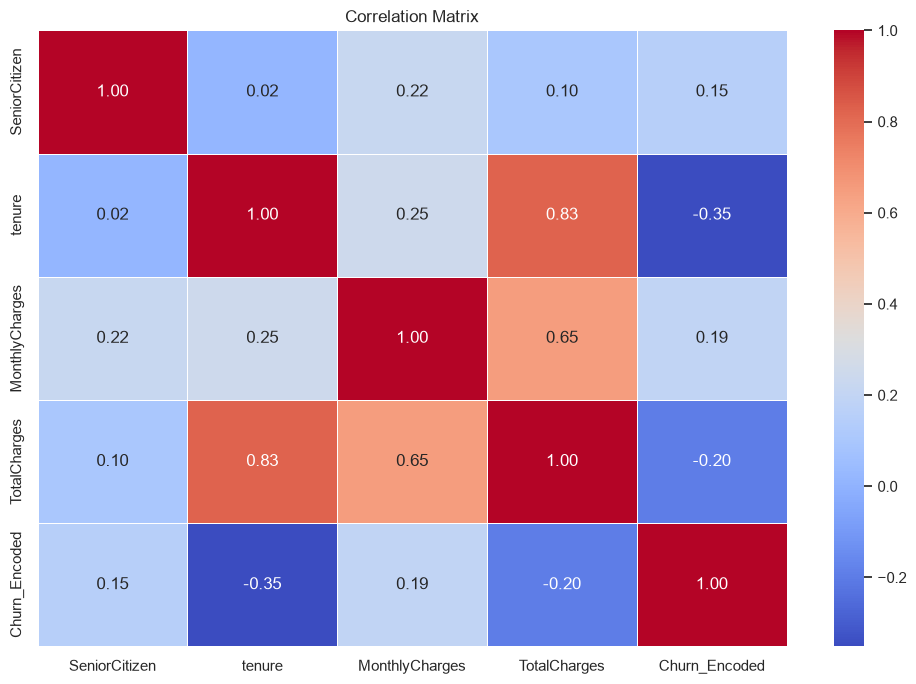

In [21]:
correlation_df = df.copy()

correlation_df["Churn_Encoded"] = (
    correlation_df["Churn"].map({
        "No": 0,
        "Yes": 1
    })
)

correlation_matrix = correlation_df[
    numerical_features + ["Churn_Encoded"]
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## 5. Feature Preprocessing

In [22]:
TARGET_COLUMN = "Churn"

numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in df.select_dtypes(include=["object"]).columns
    if col != TARGET_COLUMN
]

# Treat SeniorCitizen as a categorical feature
categorical_features.append("SeniorCitizen")

print("Numerical features:", numerical_features)
print("Number of numerical features:", len(numerical_features))

print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

print("\nTotal input features:",
      len(numerical_features) + len(categorical_features))

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Number of numerical features: 3

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'SeniorCitizen']
Number of categorical features: 16

Total input features: 19


In [24]:
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN].map({
    "No": 0,
    "Yes": 1
})

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Feature matrix shape: (7021, 19)
Target vector shape: (7021,)

Target values:
Churn
0    5164
1    1857
Name: count, dtype: int64


## 6. Test Train Split

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training samples: 5616
Testing samples: 1405

Training target distribution:
Churn
0   73.56
1   26.44
Name: proportion, dtype: float64

Testing target distribution:
Churn
0   73.52
1   26.48
Name: proportion, dtype: float64


,Training,Testing
No Churn,73.56,73.52
Churn,26.44,26.48


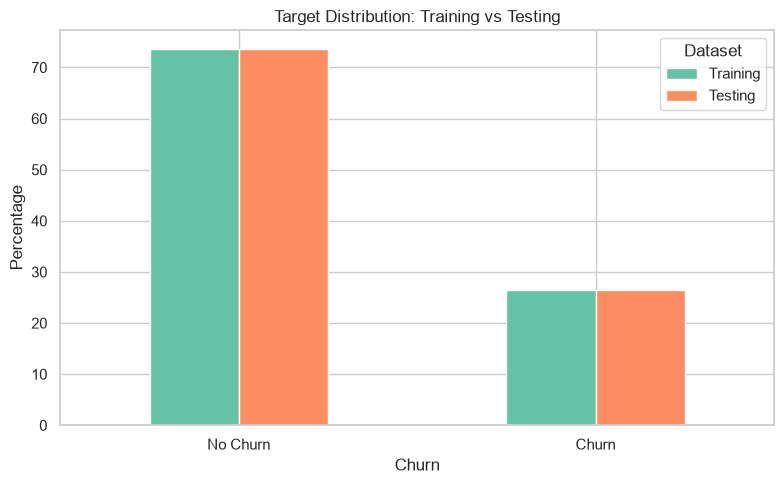

In [26]:
split_distribution = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True) * 100,
    "Testing": y_test.value_counts(normalize=True) * 100
})

split_distribution.index = ["No Churn", "Churn"]

display(split_distribution.round(2))

split_distribution.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Target Distribution: Training vs Testing")
plt.xlabel("Churn")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

## 7. Preprocessing Pipelines

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [28]:
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [29]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

In [30]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 8. Dataset Export

In [31]:
from pathlib import Path

DATA_DIR = PROJECT_ROOT / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Reconstruct datasets using original target labels
train_data = X_train.copy()
train_data[TARGET_COLUMN] = df.loc[X_train.index, TARGET_COLUMN]

test_data = X_test.copy()
test_data[TARGET_COLUMN] = df.loc[X_test.index, TARGET_COLUMN]

# Export
train_data.to_csv(DATA_DIR / "train_data.csv", index=False)
test_data.to_csv(DATA_DIR / "test_data.csv", index=False)

print("Datasets exported successfully!")

print("Training data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)

Datasets exported successfully!
Training data shape: (5616, 20)
Testing data shape: (1405, 20)


In [32]:
print("Training dataset:")
display(pd.read_csv(DATA_DIR / "train_data.csv").head())

print("\nTesting dataset:")
display(pd.read_csv(DATA_DIR / "test_data.csv").head())

print("\nExported files:")
for file in DATA_DIR.iterdir():
    if file.is_file():
        print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")

Training dataset:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,No,Credit card (automatic),70.70,140.70,Yes
1,Female,0,No,No,15,Yes,Yes,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Credit card (automatic),84.35,1302.65,No
2,Male,0,Yes,Yes,67,Yes,Yes,Fiber optic,No,Yes,No,No,No,Yes,Month-to-month,Yes,Bank transfer (automatic),89.55,6373.10,No
3,Male,0,No,No,5,Yes,No,DSL,No,Yes,No,Yes,No,Yes,Month-to-month,Yes,Bank transfer (automatic),65.60,339.90,No
4,Male,0,No,No,26,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Electronic check,20.30,511.25,No



Testing dataset:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,74.85,485.25,No
1,Male,1,No,No,19,Yes,No,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),95.90,1777.90,Yes
2,Female,0,No,Yes,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Mailed check,45.95,45.95,Yes
3,Female,0,No,No,36,Yes,No,DSL,Yes,Yes,Yes,Yes,Yes,Yes,One year,No,Bank transfer (automatic),85.85,3003.55,No
4,Female,0,Yes,Yes,70,Yes,No,DSL,Yes,Yes,Yes,Yes,No,Yes,One year,No,Credit card (automatic),74.10,5222.30,No



Exported files:
IT_customer_churn.csv - 878.92 KB
train_data.csv - 696.29 KB
test_data.csv - 173.99 KB
